# Imports

In [ ]:
import subprocess
import os
import glob
import sys
sys.path.append("..")
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from rstools import RSoftCircuit
import rsoft_lib as rlib
from pathlib import Path

import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
import pandas as pd
import linecache
import re

from tqdm import tqdm

# 2x2 MMI single input, FemSIM mode injection in left input

Scan in wavelength

In [47]:
working_dir = r"D:\DATA\ActivePIC\2x2MMI"
device_name = "2x2MMI_FiberLeftInput_v2"
prefix = f"{device_name}_pade44_halfGrid_scan_Wav"
save_dir = os.path.join(working_dir, prefix)
CAD_path = os.path.join(working_dir, f"{device_name}.ind")
# wav_arr = np.linspace(1.45, 1.65, 21)
wav_arr = np.array([1.45, 1.55, 1.65])

os.makedirs(save_dir, exist_ok=True)
Grid_size, Step_z = 0.05, 0.5

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False):
    wav_str = rlib.param_str(wav)
    rlib.run_sim(
        CAD_path,
        prefix=os.path.join(save_dir, f"{prefix}{wav_str}"),
        symbols={
            "free_space_wavelength": wav,
            "Injection_filename": rlib.mode_field(wav, 3.4)[0],   # straight-guide TE mode (.m00)
            "Grid_size": Grid_size,
            "Step_z": Step_z
        },
    )
np.save(os.path.join(save_dir, f"{device_name}_Wav.npy"), wav_arr)

Straight inputs: scan in wavelength

In [26]:
working_dir = r"D:\DATA\ActivePIC\2x2MMI"
device_name = "2x2MMI_FiberLeftInput_StraightInputs"
save_dir = os.path.join(working_dir, f"{device_name}_scan_Wav")
CAD_path = os.path.join(working_dir, f"{device_name}.ind")
wav_arr = np.linspace(1.45, 1.65, 21)

os.makedirs(save_dir, exist_ok=True)

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False):
    wav_str = rlib.param_str(wav)
    rlib.run_sim(
        CAD_path,
        prefix=os.path.join(save_dir, f"{device_name}_scan_Wav{wav_str}"),
        symbols={
            "free_space_wavelength": wav,
            "Injection_filename": rlib.mode_field(wav, 3.4)[0],   # straight-guide TE mode (.m00)
        },
    )
np.save(os.path.join(save_dir, f"{device_name}_Wav.npy"), wav_arr)

In [48]:
working_dir = r"D:\DATA\ActivePIC\2x2MMI"
device_name = "2x2MMI_FiberLeftInput_v2_pade44_halfGrid"
save_dir = os.path.join(working_dir, f"{device_name}_scan_Wav")

# Find the .mon files and the wavelength each one belongs to (every wavelength in the folder)
name_re = re.compile(r"_Wav([-\dp]+)\.mon$")
files = {}
for path in glob.glob(os.path.join(save_dir, "*.mon")):
    m = name_re.search(path)
    if m:
        files[float(m.group(1).replace("p", "."))] = path
if not files:
    raise FileNotFoundError(f"No *_Wav<x>.mon files in {save_dir}")
wavs = np.array(sorted(files))
print(f"{len(wavs)} wavelengths, {wavs.min():.3f} to {wavs.max():.3f} μm")

# Last z sample of each file. Monitor order in the .ind:
# 1 = path 1 power, 2 = path 1 phase, 3 = path 2 power, 4 = path 2 phase.
rows = np.array([rlib.read_monitor(files[w]).values[-1, :4] for w in wavs])
power_A, phase_A, power_B, phase_B = rows.T

df = pd.DataFrame({
    "wavelength_um": wavs.round(6),                      # removes float noise like 1.4999999999999998
    "power_A": power_A,
    "power_B": power_B,
    "total_loss": 1 - (power_A + power_B),               # fraction of input power not in A or B
    "total_loss_dB": -10 * np.log10(power_A + power_B),
    "phase_A_deg": phase_A,
    "phase_B_deg": phase_B,
})
csv_path = os.path.join(save_dir, f"{device_name}_outputs.csv")
df.to_csv(csv_path, index=False)
print(f"Wrote {csv_path}")

3 wavelengths, 1.450 to 1.650 μm
Wrote D:\DATA\ActivePIC\2x2MMI\2x2MMI_FiberLeftInput_v2_pade44_halfGrid_scan_Wav\2x2MMI_FiberLeftInput_v2_pade44_halfGrid_outputs.csv


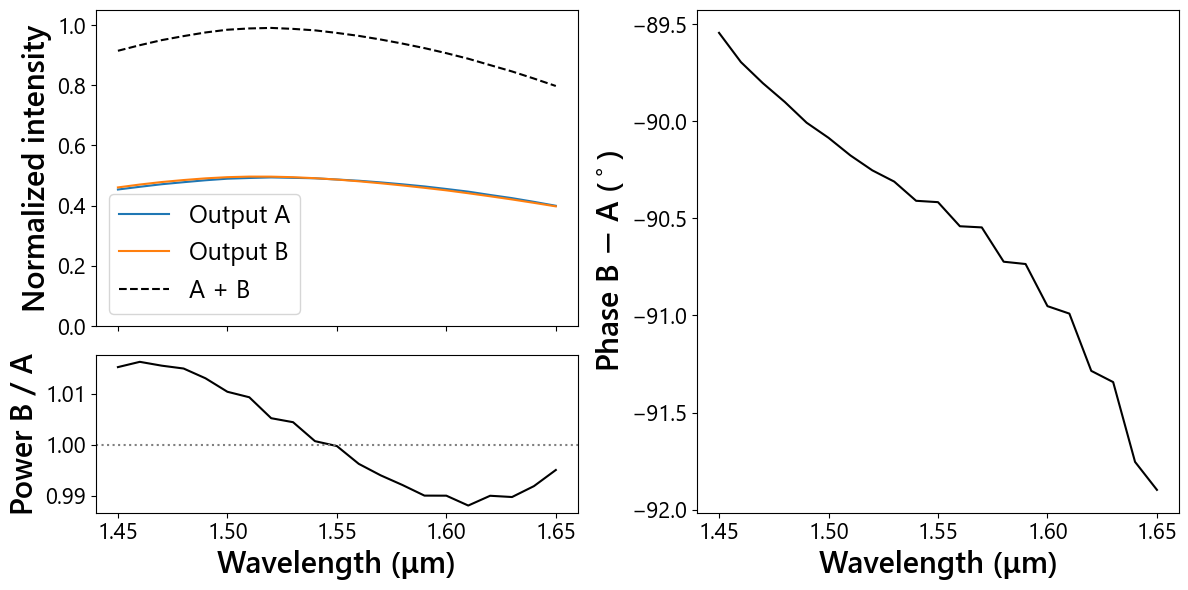

In [38]:
# Load the results written by the export script
df = pd.read_csv(os.path.join(save_dir, f"{device_name}_outputs.csv"))
wavs = df.wavelength_um.to_numpy()
power_A, power_B = df.power_A.to_numpy(), df.power_B.to_numpy()
phase_A, phase_B = df.phase_A_deg.to_numpy(), df.phase_B_deg.to_numpy()

# Relative phase between the outputs, wrapped to (-180, 180]
dphase = np.rad2deg(np.angle(np.exp(1j * np.deg2rad(phase_B - phase_A))))

fig = plt.figure(figsize=(12, 6))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.5])
ax_pow = fig.add_subplot(gs[0, 0])
ax_ratio = fig.add_subplot(gs[1, 0], sharex=ax_pow)
ax_phase = fig.add_subplot(gs[:, 1])

# Top left: output powers
ax_pow.plot(wavs, power_A, label="Output A")
ax_pow.plot(wavs, power_B, label="Output B")
ax_pow.plot(wavs, power_A + power_B, "k--", label="A + B")
ax_pow.set_ylabel("Normalized intensity")
ax_pow.set_ylim(0, 1.05)
ax_pow.legend()
ax_pow.tick_params(labelbottom=False)

# Bottom left: power ratio
with np.errstate(divide="ignore", invalid="ignore"):
    ratio = power_B / power_A
ax_ratio.plot(wavs, ratio, color="k")
ax_ratio.axhline(1, linestyle="dotted", color="gray")      # equal split
ax_ratio.set_ylabel("Power B / A")
ax_ratio.set_xlabel(r"Wavelength (μm)")

# Right: relative phase
ax_phase.plot(wavs, dphase, color='k')
ax_phase.set_ylabel(r"Phase B $-$ A ($^\circ$)")
ax_phase.set_xlabel(r"Wavelength (μm)")

plt.tight_layout()
plt.show()

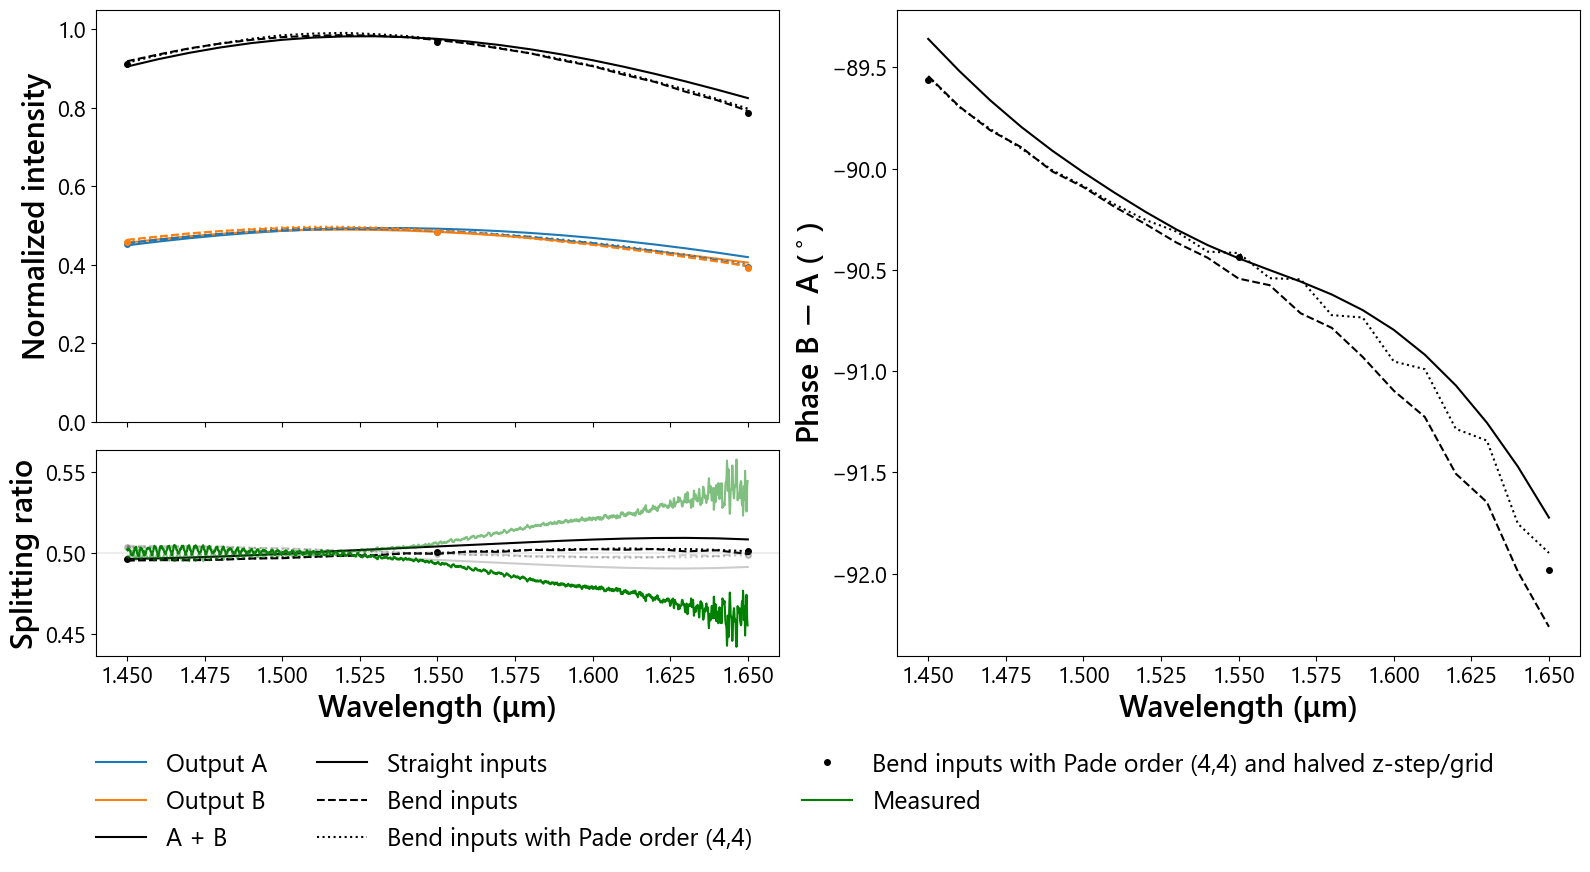

In [77]:
csv_path = f"D:\\DATA\\ActivePIC\\2x2MMI\\Device20_2x2MMI_splittingRatio.csv"
meas = pd.read_csv(csv_path).sort_values("wavelength_nm")
columnA, columnB = "fraction_O37", "fraction_O38"
w, f_A, f_B = meas.wavelength_nm.to_numpy()/1000, meas[columnA].to_numpy(), meas[columnB].to_numpy()

working_dir = r"D:\DATA\ActivePIC\2x2MMI"
devices = {                                   # label -> (device name, plot style)
    "Straight inputs": ("2x2MMI_FiberLeftInput_StraightInputs", dict(linestyle="-")),
    "Bend inputs": ("2x2MMI_FiberLeftInput_v2", dict(linestyle="--")),
    "Bend inputs with Pade order (4,4)": ("2x2MMI_FiberLeftInput_v2_pade44", dict(linestyle="dotted")),
    "Bend inputs with Pade order (4,4) and halved z-step/grid": ("2x2MMI_FiberLeftInput_v2_pade44_halfGrid",
                                                         dict(linestyle="none", marker="o", markersize=4)),   # markers only
}

fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.5])
ax_pow = fig.add_subplot(gs[0, 0])
ax_ratio = fig.add_subplot(gs[1, 0], sharex=ax_pow)
ax_phase = fig.add_subplot(gs[:, 1])

for label, (device_name, style) in devices.items():
    # Load the results written by the export script for this device
    save_dir = os.path.join(working_dir, f"{device_name}_scan_Wav")
    df = pd.read_csv(os.path.join(save_dir, f"{device_name}_outputs.csv"))
    wavs = df.wavelength_um.to_numpy()
    power_A, power_B = df.power_A.to_numpy(), df.power_B.to_numpy()
    phase_A, phase_B = df.phase_A_deg.to_numpy(), df.phase_B_deg.to_numpy()

    # Relative phase between the outputs, wrapped to (-180, 180]
    dphase = np.rad2deg(np.angle(np.exp(1j * np.deg2rad(phase_B - phase_A))))
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio_A = power_A / (power_A + power_B)
        ratio_B = power_B / (power_A + power_B)

    # Top left: output powers
    ax_pow.plot(wavs, power_A, color="C0", **style)
    ax_pow.plot(wavs, power_B, color="C1", **style)
    ax_pow.plot(wavs, power_A + power_B, color="k", **style)
    # Bottom left: power ratio
    ax_ratio.plot(wavs, ratio_A, color="k", **style)
    ax_ratio.plot(wavs, ratio_B, color="k", alpha=0.2, **style)
    # Right: relative phase
    ax_phase.plot(wavs, dphase, color="k", **style)

meas_line, = ax_ratio.plot(w, f_A/(f_A + f_B), color="g", label='Measured')   # keep the line handle
ax_ratio.plot(w, f_B/(f_A + f_B), color="g", alpha=0.5)

# Colors identify the output, line styles (or markers) identify the input type
handles = ([Line2D([], [], color="C0", label="Output A"),
            Line2D([], [], color="C1", label="Output B"),
            Line2D([], [], color="k", label="A + B")]
           + [Line2D([], [], color="k", label=label, **style) for label, (_, style) in devices.items()]
           + [meas_line])                                                          # add the measured line
ax_pow.set_ylabel("Normalized intensity")
ax_pow.set_ylim(0, 1.05)
ax_pow.tick_params(labelbottom=False)

ax_ratio.axhline(0.5, color="gray", linewidth=0.2)      # equal split
ax_ratio.set_ylabel("Splitting ratio")
ax_ratio.set_xlabel(r"Wavelength (μm)")

ax_phase.set_ylabel(r"Phase B $-$ A ($^\circ$)")
ax_phase.set_xlabel(r"Wavelength (μm)")

fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.0, 1, 1))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

# (b) 2x2 MMI single input, splitter output injection in right input

Scan in wavelength and phase

In [10]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
filename = "2x2MMI_OneInput.ind"

wav = rsoft_lib.read_symbol(working_dir+filename, "free_space_wavelength")
phase = rsoft_lib.read_symbol(working_dir+filename, "PhaseShift")
TaperGap = rsoft_lib.read_symbol(working_dir+filename, "TaperGap")
TaperWidth = rsoft_lib.read_symbol(working_dir+filename, "TaperWidth")
BendOffset = rsoft_lib.read_symbol(working_dir+filename, "BendOffset")
waveguide_width = rsoft_lib.read_symbol(working_dir+filename, "width")

launch_position = 2*(((MMISlabWidth-TaperWidth)/2)+BendOffset)

ValueError: could not convert string to float: ' width\n'

# Apply phase shift in one output and scan tricoupler in wavelength and phase

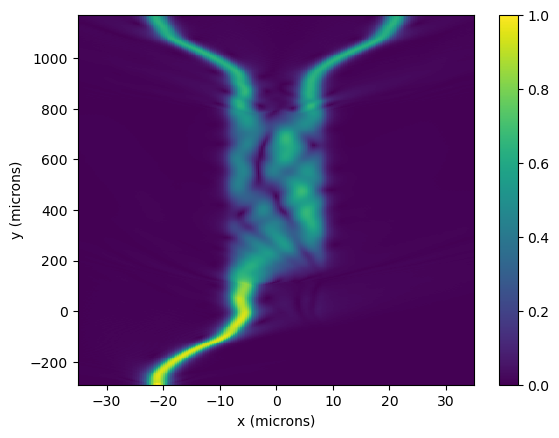

In [12]:
# filename = working_dir+save_dir+"\\2x2MMI_OneInput_scan_Wav1p550_xz.dat"
filename = "C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_scan_Wav_Phase\\2x2MMI_OneInput_scan_Wav_Phase_Wav1p480_Phase0p000_xz.dat"
data = np.genfromtxt(filename, delimiter='', skip_header=4).T
x_line = linecache.getline(filename, 3)
y_line = linecache.getline(filename, 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

plt.figure()
im = plt.pcolormesh(x, y, data, vmin=0, vmax=1)
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

In [12]:
# Tricoupler input parameters
TaperGap, TaperWidth, BendOffset = 7, 5, 15
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset
waveguide_width, waveguide_height = 3.4, 3.4

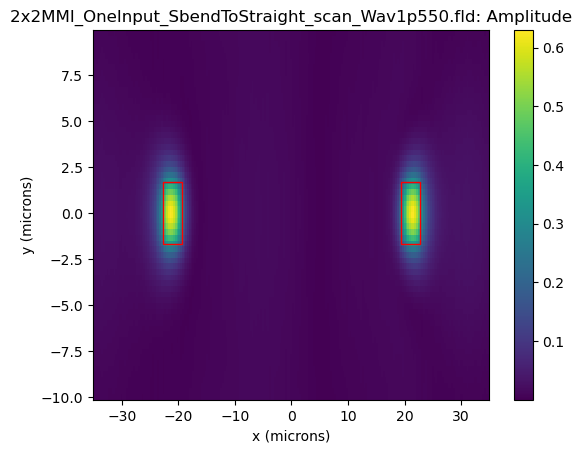

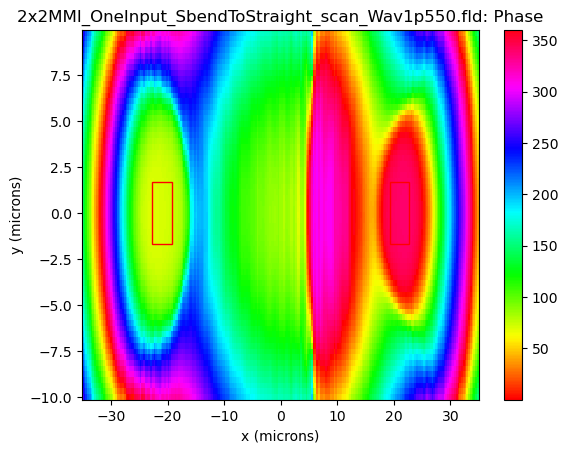

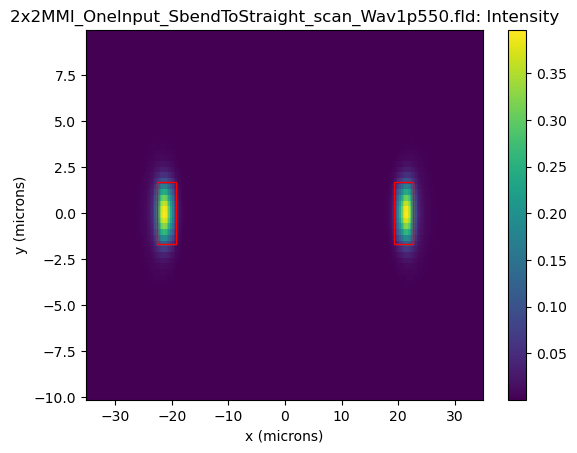

0.39652964643599997

In [101]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_SbendToStraight\\"
save_dir = "2x2MMI_OneInput_SbendToStraight_scan_Wav"
filenames_field = glob.glob(working_dir+save_dir+f"\\{save_dir}1p550.fld")

field = np.genfromtxt(filenames_field[0], skip_header=4)
n_rows, n_cols = np.shape(field)
field_amp, field_phase = field[:, ::2].T, field[:, 1::2].T
x_line = linecache.getline(filenames_field[0], 3)
y_line = linecache.getline(filenames_field[0], 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

field = field_amp*np.exp(1j*field_phase*np.pi/180)
intensity = np.absolute(field)**2.

fig, ax = plt.subplots()
im = plt.pcolormesh(x, y, field_amp)
square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
ax.add_patch(square_left)
ax.add_patch(square_right)
plt.title(filenames_field[0].split('\\')[-1] + ": Amplitude")
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

fig, ax = plt.subplots()
im = plt.pcolormesh(x, y, field_phase, cmap='hsv')
square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
ax.add_patch(square_left)
ax.add_patch(square_right)
plt.title(filenames_field[0].split('\\')[-1] + ": Phase")
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

fig, ax = plt.subplots()
im = plt.pcolormesh(x, y, intensity)
square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                linewidth=1, edgecolor='r', facecolor='none')
square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                 linewidth=1, edgecolor='r', facecolor='none')
ax.add_patch(square_left)
ax.add_patch(square_right)
plt.title(filenames_field[0].split('\\')[-1] + ": Intensity")
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

np.max(intensity)

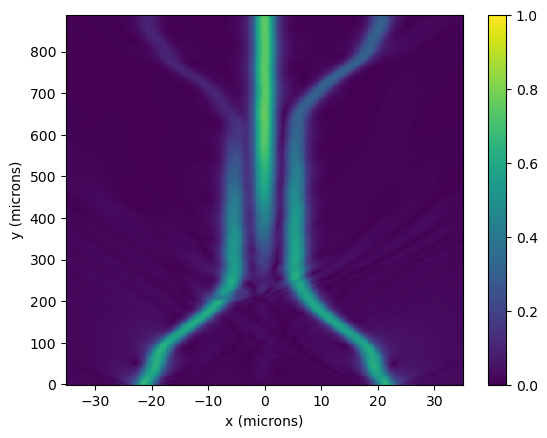

In [8]:
# filename = working_dir+save_dir+"\\2x2MMI_OneInput_scan_Wav1p550_xz.dat"
filename = "C:\\Users\\runner\\ActivePIC\\Device11_4a_1x3Tricoupler\\Device11_4a_1x3Tricoupler_scan_Wav_Phase\\Device11_4a_1x3Tricoupler_scan_Wav1p550_Phase0p000_xz.dat"
data = np.genfromtxt(filename, delimiter='', skip_header=4).T
x_line = linecache.getline(filename, 3)
y_line = linecache.getline(filename, 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

plt.figure()
im = plt.pcolormesh(x, y, data, vmin=0, vmax=1)
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()

(227,) (404,) (404,)


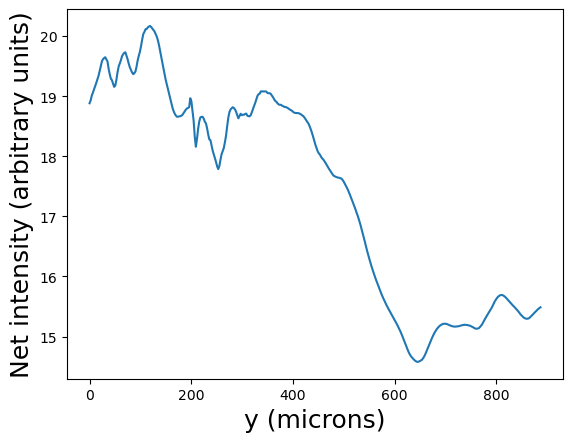

In [9]:
y_profile = np.sum(data, axis=1)
print(np.shape(x), np.shape(y), np.shape(y_profile))

plt.figure()
plt.plot(y, y_profile)
plt.xlabel('y (microns)', fontsize=18)
plt.ylabel('Net intensity (arbitrary units)', fontsize=18)
plt.show()

In [46]:
TaperGap, TaperWidth, TaperLength, BendOffset, BendLength = 7, 5, 100, 15, 289.4391128
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset
MMISlabWidth, MMISlabLength = 17, 682
waveguide_width, waveguide_height = 3.4, 3.4

In [74]:
tricoupler_right_x

21.0

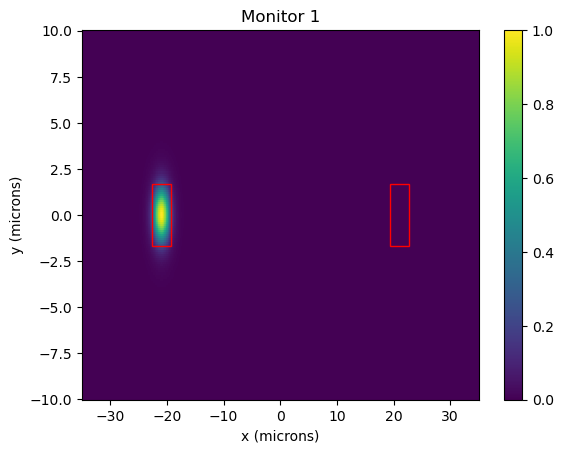

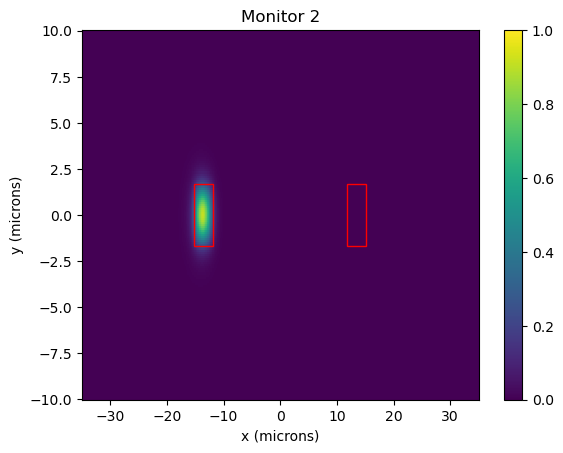

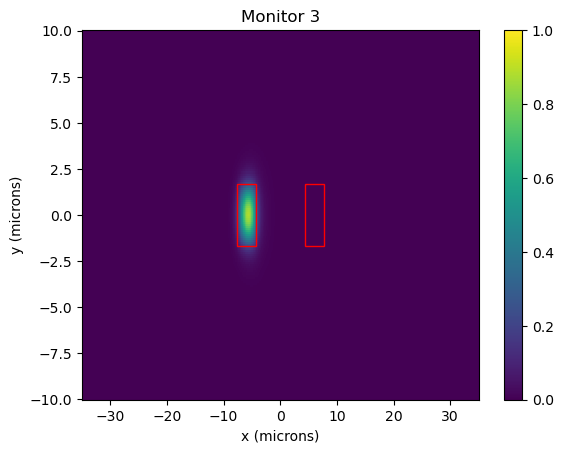

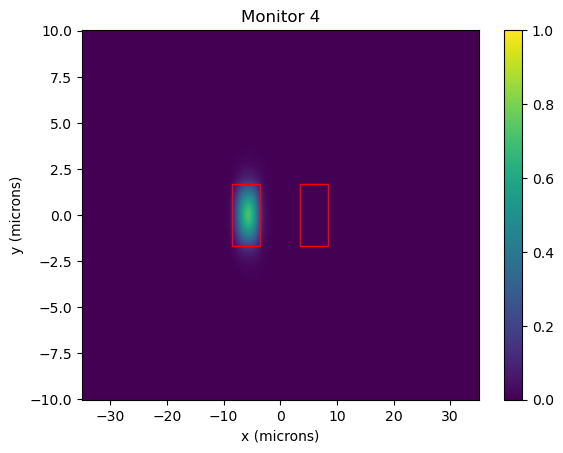

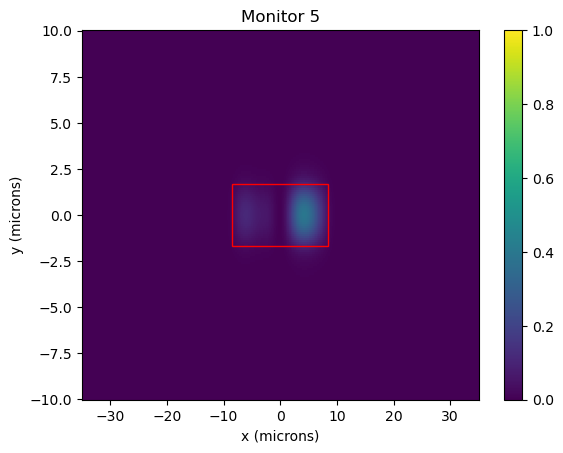

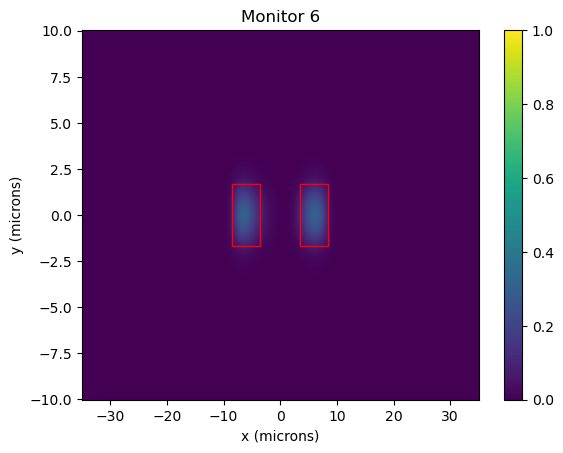

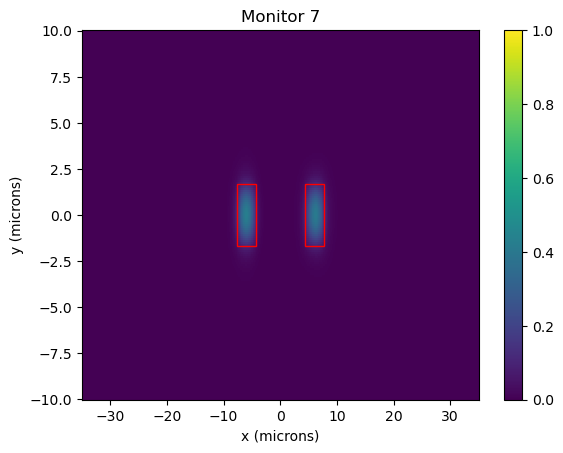

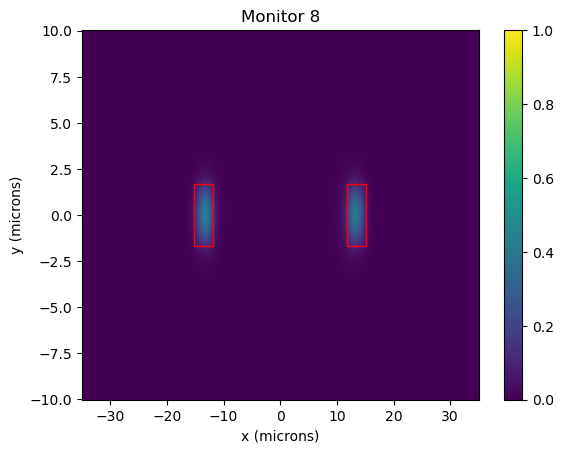

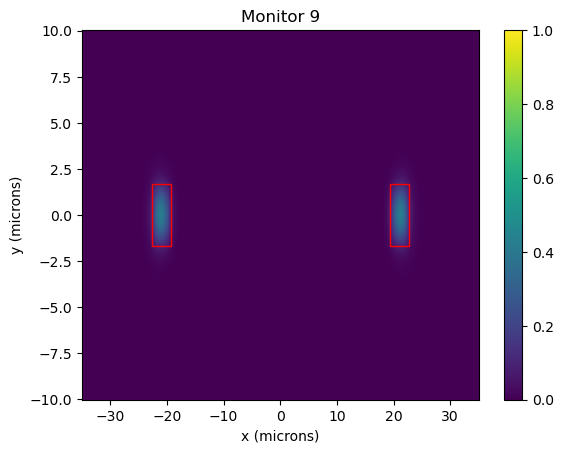

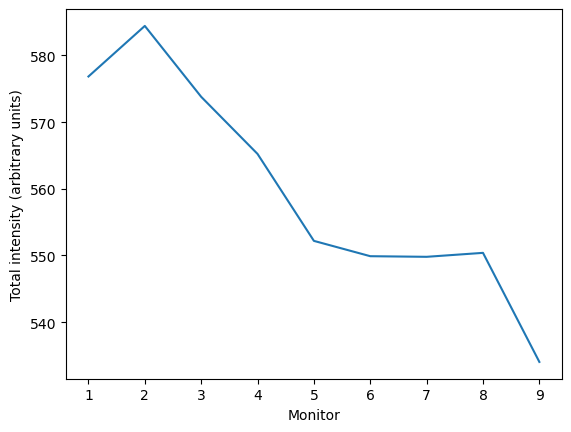

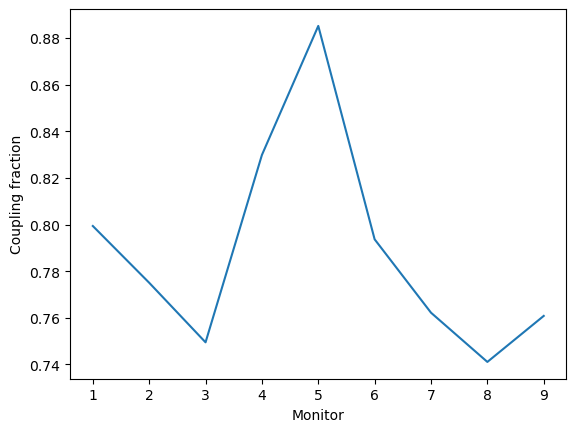

In [97]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = ""

total_powers = []
waveguides = [[[tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[tricoupler_left_x+BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height], [(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height]],
              [[-MMISlabWidth/2, 0-waveguide_height/2, MMISlabWidth, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height], [(TaperGap+TaperWidth)/2-TaperWidth/2, 0-waveguide_height/2, TaperWidth, waveguide_height]],
              [[-(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [(TaperGap+TaperWidth)/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[tricoupler_left_x+BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-BendOffset/2-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]],
              [[tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height], [tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2, waveguide_width, waveguide_height]]]
coupled = []
output_A, output_B = [], []
for i, monitor in enumerate(np.arange(10, 19)):
    filename = working_dir+save_dir+f"\\2x2MMI_OneInput_GUI_m{monitor}_ex.dat"
    data = np.genfromtxt(filename, delimiter='', skip_header=4).T
    ex_amp = data[::2]
    ex_phase = data[1::2]
    Ex = ex_amp*np.exp(1j*ex_phase*np.pi/180)

    filename = working_dir+save_dir+f"\\2x2MMI_OneInput_GUI_m{monitor}_ey.dat"
    data = np.genfromtxt(filename, delimiter='', skip_header=4).T
    ey_amp = data[::2]
    ey_phase = data[1::2]
    Ey = ey_amp*np.exp(1j*ey_phase*np.pi/180)

    filename = working_dir+save_dir+f"\\2x2MMI_OneInput_GUI_m{monitor}_ez.dat"
    data = np.genfromtxt(filename, delimiter='', skip_header=4).T
    ez_amp = data[::2]
    ez_phase = data[1::2]
    Ez = ez_amp*np.exp(1j*ez_phase*np.pi/180)
    
    intensity = np.absolute(Ex)**2 + np.absolute(Ey)**2 + np.absolute(Ez)**2
    
    x_line = linecache.getline(filename, 3)
    y_line = linecache.getline(filename, 4)
    x_line_split = x_line.split(' ')
    y_line_split = y_line.split(' ')
    x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
    y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

    total_powers.append(intensity.sum())
    
    fig, ax = plt.subplots()
    im = plt.pcolormesh(x, y, intensity, vmin=0, vmax=1)#, norm=LogNorm(vmin=1e-7, vmax=1))
    in_waveguides = 0 
    tot_intensity = np.copy(np.sum(intensity))
    for o, waveguide in enumerate(waveguides[i]):
        patch = patches.Rectangle((waveguide[0], waveguide[1]), waveguide[2], waveguide[3],
                                linewidth=1, edgecolor='r', facecolor='none')
        ax.add_patch(patch)
        field_x = abs(x-(waveguide[0] + waveguide[2]/2)) < waveguide[2]/2.
        field_y = abs(y-(waveguide[1] + waveguide[3]/2)) < waveguide[3]/2.
        in_waveguides += np.sum(intensity[np.ix_(field_y, field_x)])/tot_intensity
        if (o==0 and len(waveguides[i])==2):
            output_A.append(np.sum(intensity[np.ix_(field_y, field_x)])/tot_intensity)
        elif (o==1 and len(waveguides[i])==2):
            output_B.append(np.sum(intensity[np.ix_(field_y, field_x)])/tot_intensity)
    coupled.append(in_waveguides)

    plt.xlabel('x (microns)')
    plt.ylabel('y (microns)')
    plt.colorbar(im)
    plt.title(f"Monitor {i+1}")
    plt.show()


plt.figure()
plt.plot(np.arange(1,10), total_powers)
plt.xlabel('Monitor')
plt.ylabel('Total intensity (arbitrary units)')
plt.show()

plt.figure()
plt.plot(np.arange(1,10), coupled)
plt.xlabel('Monitor')
plt.ylabel('Coupling fraction')
plt.show()

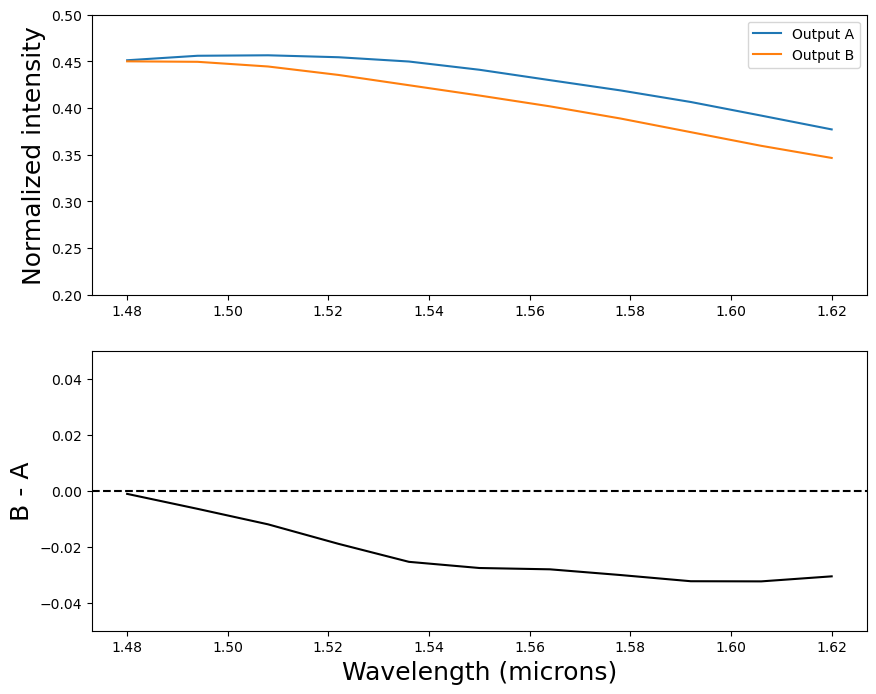

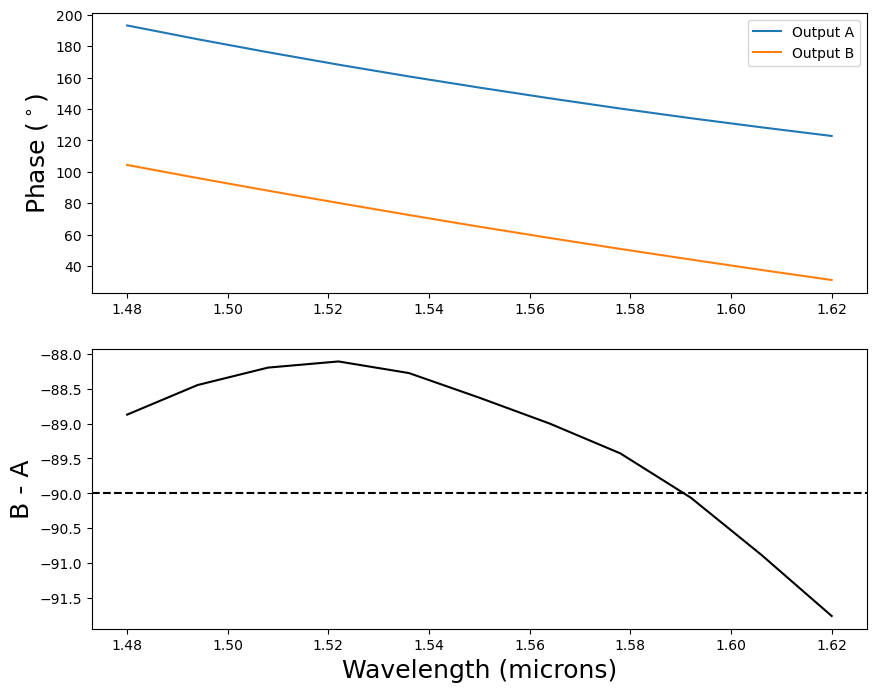

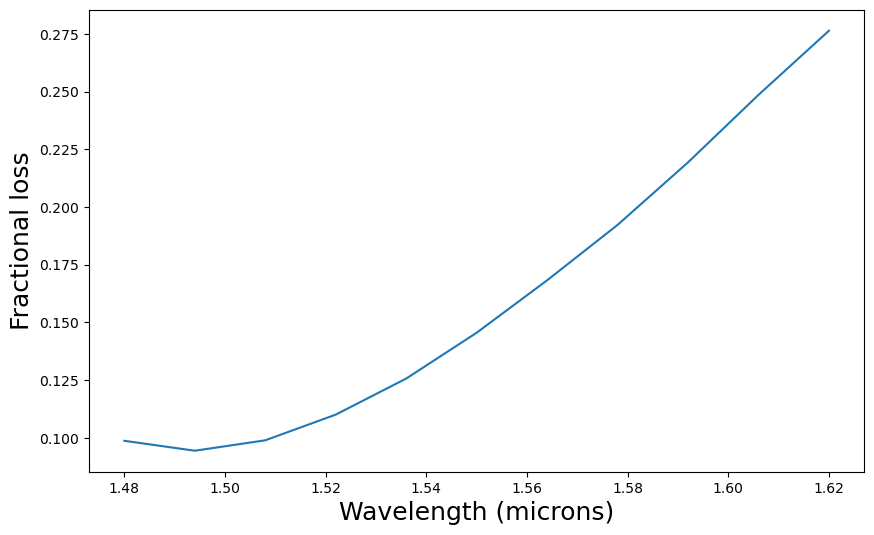

In [12]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = "2x2MMI_OneInput_scan_Wav_Phase"
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"
norm_filename = norm_dir+f"StraightWaveguide_scan_Wav1p550.mon"
norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
norm = norm_mon[-1, 1]

filenames_mon = glob.glob(working_dir+save_dir+"\*_Phase0p000.mon")
wav, power_A, power_B, phase_A, phase_B = [], [], [], [], []

for filename in filenames_mon:
    data = np.genfromtxt(filename, delimiter='', skip_header=5)
    wav.append(float(filename.split('Wav')[-1].split('_')[0].replace('p', '.')))
    power_A.append(data[-1, 1])
    power_B.append(data[-1, 2])
    phase_A.append(data[-1, 3])
    phase_B.append(data[-1, 4])
wav, power_A, power_B, phase_A, phase_B = np.array(wav), np.array(power_A)/norm, np.array(power_B)/norm, np.array(phase_A), np.array(phase_B)
# phase_A[phase_A>180] = phase_A[phase_A>180] - 360
# phase_B[phase_B>180] = phase_B[phase_B>180] - 360

# Plot power from all outputs
fontsize = 18
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(nrows=2, ncols=1, height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0])
ax1.plot(wav, power_A, label='Output A')
ax1.plot(wav, power_B, label='Output B')
ax1.set_ylim(0.2, 0.5)
ax1.set_ylabel('Normalized intensity', fontsize=fontsize)
ax1.legend()

ax2 = fig.add_subplot(gs[1], sharex=ax1) # Optional: share the x-axis for alignment
ax2.plot(wav, power_B - power_A, color='k')
ax2.axhline(0, linestyle='dashed', color='black')
ax2.set_ylim(-0.05, 0.05)
ax2.set_ylabel('B - A', fontsize=fontsize)
ax2.set_xlabel('Wavelength (microns)', fontsize=fontsize)
plt.show()

# Plot phase from all outputs
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(nrows=2, ncols=1, height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0])
ax1.plot(wav, phase_A, label='Output A')
ax1.plot(wav, phase_B, label='Output B')
ax1.set_ylabel(r'Phase ($^\circ$)', fontsize=fontsize)
ax1.legend()

ax2 = fig.add_subplot(gs[1], sharex=ax1) # Optional: share the x-axis for alignment
ax2.plot(wav, phase_B - phase_A, color='k')
ax2.axhline(-90, linestyle='dashed', color='black')
# ax2.set_ylim(-10, 10)
ax2.set_ylabel('B - A', fontsize=fontsize)
ax2.set_xlabel('Wavelength (microns)', fontsize=fontsize)
plt.show()

# Plot loss
fig, ax = plt.subplots(1, 1, figsize=(10,6))
plt.plot(wav, 1 - (power_A + power_B))
plt.xlabel('Wavelength (microns)', fontsize=fontsize)
plt.ylabel('Fractional loss', fontsize=fontsize)
plt.show()


Final throughput: 0.9264532405830433


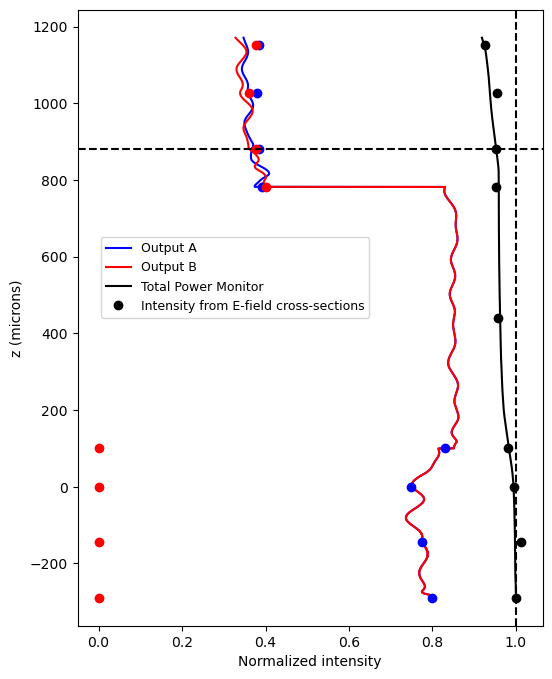

In [163]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI"
save_dir = ""
filename = working_dir+save_dir+'\\2x2MMI_OneInput_GUI.mon'
norm_dir = r"C:\\Users\\runner\\ActivePIC\\StraightWaveguide\\StraightWaveguide_scan_Wav\\"

data = np.genfromtxt(filename, delimiter='', skip_header=5)
z = data[:, 0]
power_A = data[:, 1]
power_B = data[:, 2]
power_tot = data[:, -1]

norm_filename = norm_dir+f"StraightWaveguide_scan_Wav1p550.mon"
norm_mon = np.genfromtxt(norm_filename, delimiter='', skip_header=5)
norm = norm_mon[-1, 1]

z_mon = [-BendLength, -BendLength/2, 0, TaperLength, TaperLength+(MMISlabLength/2), TaperLength+MMISlabLength, 2*TaperLength+MMISlabLength,
         2*TaperLength+MMISlabLength+BendLength/2, 2*TaperLength+MMISlabLength+BendLength-20]
total_powers = np.array(total_powers)

z_ind = np.argmin(abs(z-(z_mon[-3])))
print('Final throughput:', (power_A[z_ind] + power_B[z_ind])/norm)

plt.figure(figsize=(6,8))
plt.plot(power_A, z, 'b', label='Output A')
plt.plot(power_B, z, 'r', label='Output B')
# plt.plot(power_A + power_B, z, label='Sum')
plt.plot(power_tot, z, 'k', label='Total Power Monitor')
plt.plot(total_powers/total_powers[0], z_mon, 'ko', label='Intensity from E-field cross-sections')
plt.plot(output_A, np.hstack([z_mon[:4], z_mon[-4:]]), 'bo')
plt.plot(output_B, np.hstack([z_mon[:4], z_mon[-4:]]), 'ro')
plt.axvline(1, linestyle='dashed', color='k')
plt.axhline(z[z_ind], linestyle='dashed', color='k')
plt.xlabel('Normalized intensity')
plt.ylabel('z (microns)')
plt.legend(loc=(0.05, 0.5), fontsize=9)
plt.show()



In [165]:
power_A[0], norm

(0.8003888, 0.7847307)